[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_frontier/BA_L4_frontier.ipynb)

# BA_L4_frontier: Does Bitcoin improve the efficient frontier?

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Long-only minimum-variance frontiers of the S&P 500 and Treasuries (TLT), with and without Bitcoin, from annualised means and covariances of daily simple returns on common trading days 2018 to 18 September 2026.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Data.** S&P 500 index (price index, no dividends), the iShares 20+ Year Treasury Bond ETF (TLT, adjusted close: distributions reinvested) and Bitcoin, on their common trading days from 2 January 2018 to 18 September 2026.
Daily **simple** returns $R_t = P_t/P_{t-1} - 1$, so that with daily rebalancing the portfolio return is exactly $w^\top R_t$.

**Method.** Annualised mean $\mu = 252\,\bar R$ and covariance $\Sigma = 252\,\hat\Sigma_{\text{daily}}$. For 40 target means $m$ between the lowest and the highest asset mean we solve
$$ \min_w\ w^\top\Sigma w \quad \text{s.t.}\quad \mathbf 1^\top w = 1,\ \ \mu^\top w = m,\ \ w \ge 0 $$
(sequential least squares programming, SLSQP), once with two assets and once with Bitcoin added.

**How to read.** Each curve gives the lowest volatility for each mean return; diamonds mark the single assets. The means are in-sample, so the gap between the curves is an upper bound on the benefit of adding Bitcoin.

In [4]:
END = '2026-09-18'


def adjusted(sym, end):
    # adjusted close (distributions reinvested) from data/market/<sym>.csv
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['adjusted_close']
    return p[p > 0].loc[:end]


px = pd.concat({'S&P 500': daily('GSPC.INDX', END), 'Treasuries (TLT)': adjusted('TLT.US', END),
                'Bitcoin': daily('BTC-USD.CC', END)}, axis=1).dropna()
X = (100 * px.pct_change()).dropna().loc['2018-01-01':]          # daily simple returns, %
print(f'common days: {len(X)}, {X.index[0].date()} - {X.index[-1].date()}')

common days: 2190, 2018-01-02 - 2026-09-18


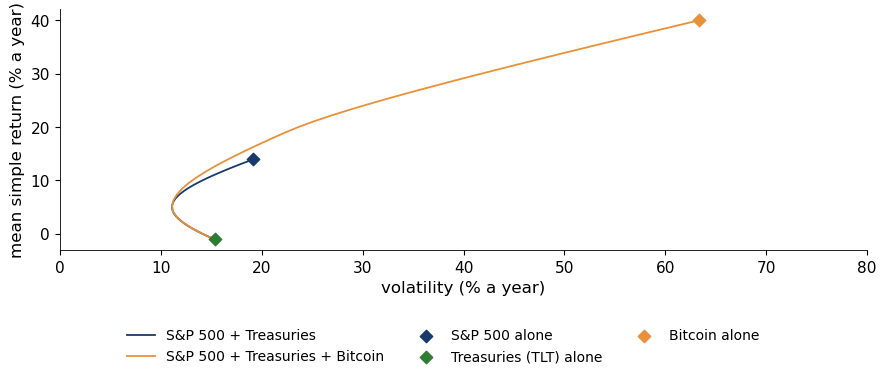

In [5]:
from scipy.optimize import minimize
mu_a = X.mean().values * 252 / 100; S_a = X.cov().values * 252 / 1e4


def frontier(ix):
    # long-only minimum variance for 40 target means between the lowest and highest asset mean
    mus = np.linspace(mu_a[ix].min(), mu_a[ix].max(), 40); vols = []
    for target in mus:
        n_ = len(ix)
        cons = [{'type': 'eq', 'fun': lambda w: w.sum() - 1}, {'type': 'eq', 'fun': lambda w, t=target: w @ mu_a[ix] - t}]
        r_ = minimize(lambda w: w @ S_a[np.ix_(ix, ix)] @ w, np.ones(n_) / n_, constraints=cons,
                      bounds=[(0, 1)] * n_, method='SLSQP')
        vols.append(np.sqrt(r_.fun) if r_.success else np.nan)
    return np.array(vols), mus


v2, m2 = frontier([0, 1]); v3, m3 = frontier([0, 1, 2])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(100 * v2, 100 * m2, color=BLUE, label='S&P 500 + Treasuries')
ax.plot(100 * v3, 100 * m3, color=BTC, label='S&P 500 + Treasuries + Bitcoin')
for i_, (nm, col) in enumerate([('S&P 500', BLUE), ('Treasuries (TLT)', GREEN), ('Bitcoin', BTC)]):
    ax.scatter(100 * np.sqrt(S_a[i_, i_]), 100 * mu_a[i_], color=col, s=40, zorder=5, marker='D', label=f'{nm} alone')
ax.set_xlabel('volatility (% a year)'); ax.set_ylabel('mean simple return (% a year)'); ax.set_xlim(0, 80)
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.16, 1, 1))
save_fig(fig, 'ba_l4_frontier')

**Key numbers** (as on the slide). The compound growth of the net asset value (NAV) is $(\mathrm{NAV}_T/\mathrm{NAV}_0)^{1/\text{years}} - 1$.

In [6]:
nav = (1 + X / 100).cumprod()                                     # net asset value of 1 USD invested on 2 Jan 2018
yrs = (X.index[-1] - X.index[0]).days / 365.25
pd.DataFrame({'mean simple return (% a year)': 100 * mu_a, 'volatility (% a year)': 100 * np.sqrt(np.diag(S_a)),
              'compound NAV growth (% a year)': 100 * (nav.iloc[-1] ** (1 / yrs) - 1)}, index=X.columns).round(1)

,mean simple return (% a year),volatility (% a year),compound NAV growth (% a year)
S&P 500,13.9,19.2,12.8
Treasuries (TLT),-1.1,15.3,-2.2
Bitcoin,40.0,63.3,21.7
